# 🚗 AutoPrice — Exploratory Data Analysis
What drives the price of a used car in this dataset? This notebook explores `Cleaned_car.csv` (Cars24 listings) before modelling.

**Columns:** `Car Name`, `Year`, `Distance` (km driven), `Owner` (1 = first owner), `Fuel`, `Drive` (transmission), `Type` (body type), `Price` (₹, target).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ACCENT, DARK, MUTED = "#c9a96e", "#2b2b30", "#9a9aa3"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": DARK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.prop_cycle": plt.cycler(color=[ACCENT, DARK, MUTED]),
})
lakh = FuncFormatter(lambda v, _: f"₹{v/1e5:.0f}L")   # 1 lakh = 1,00,000

df = pd.read_csv("../data/Cleaned_car.csv", index_col=0)
df["Brand"] = df["Car Name"].str.split().str[0]
df.shape

(8014, 9)

## 1. Data overview

In [2]:
df.head()

,Car Name,Year,Distance,Owner,Fuel,Drive,Type,Price,Brand
0,Maruti S PRESSO,2022.0,3878,1,PETROL,Manual,HatchBack,514000,Maruti
1,Hyundai Xcent,2018.0,32041,1,PETROL,Manual,Sedan,674000,Hyundai
2,Tata Safari,2021.0,96339,1,DIESEL,Automatic,SUV,1952000,Tata
3,Maruti Vitara Brezza,2019.0,51718,1,DIESEL,Manual,SUV,690000,Maruti
4,Tata Tiago,2021.0,19811,1,PETROL,Manual,HatchBack,526000,Tata


In [3]:
print(df.isna().sum().to_string(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Distinct car models:", df['Car Name'].nunique(), "| brands:", df['Brand'].nunique())
df.describe().round(0)

Car Name    0
Year        0
Distance    0
Owner       0
Fuel        0
Drive       0
Type        0
Price       0
Brand       0 

Duplicate rows: 0
Distinct car models: 126 | brands: 16


,Year,Distance,Owner,Price
count,8014.0,8014.0,8014.0,8014.0
mean,2017.0,52626.0,1.0,574833.0
std,3.0,29182.0,1.0,265084.0
min,2010.0,0.0,1.0,119000.0
25%,2015.0,30737.0,1.0,393000.0
50%,2017.0,50370.0,1.0,535000.0
75%,2019.0,71762.0,2.0,698000.0
max,2023.0,971212.0,4.0,3300000.0


## 2. The target: Price

Median ₹535,000 | mean ₹574,833 | skew 1.75


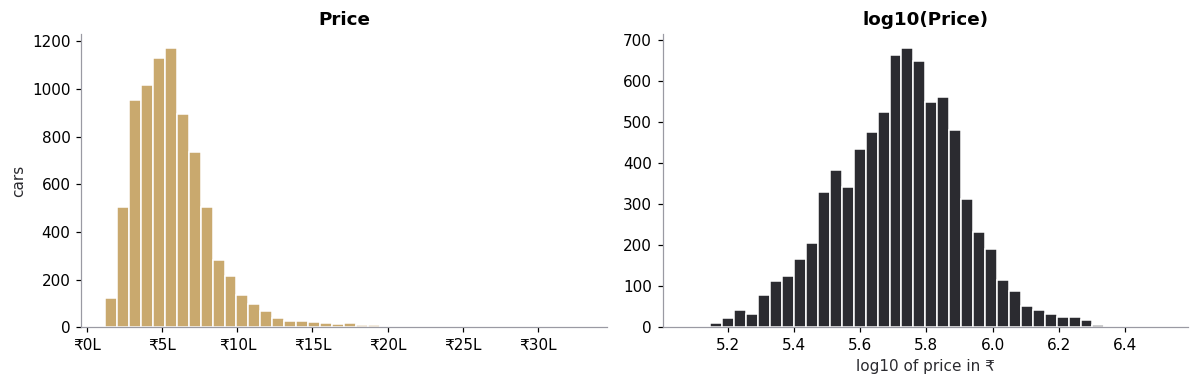

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df["Price"], bins=40, color=ACCENT, edgecolor="white")
ax[0].xaxis.set_major_formatter(lakh); ax[0].set_title("Price"); ax[0].set_ylabel("cars")
ax[1].hist(np.log10(df["Price"]), bins=40, color=DARK, edgecolor="white")
ax[1].set_title("log10(Price)"); ax[1].set_xlabel("log10 of price in ₹")
plt.tight_layout()
print(f"Median ₹{df.Price.median():,.0f} | mean ₹{df.Price.mean():,.0f} | skew {df.Price.skew():.2f}")

Prices are **right-skewed**: many affordable cars and a long tail of premium ones. On a log scale the shape is far more symmetric — which is why the training script tests a *log-price* target.

## 3. Year and age

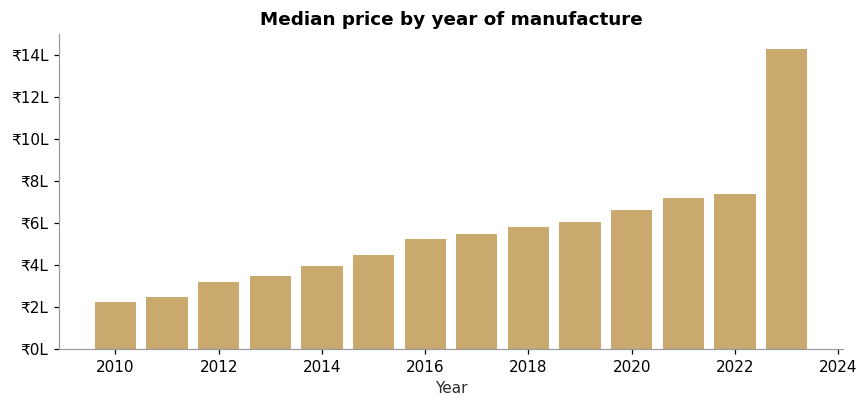

Year,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0
median price (₹),223500,249000,320000,348000,397500,450000,522000,546000,579000,604000,663000,717000,736325,1427000
listings,174,218,294,353,528,614,903,1161,1206,1010,613,683,256,1


In [5]:
g = df.groupby("Year")["Price"].agg(["median", "size"])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(g.index.astype(int), g["median"], color=ACCENT)
ax.yaxis.set_major_formatter(lakh); ax.set_title("Median price by year of manufacture"); ax.set_xlabel("Year")
plt.tight_layout()
g.rename(columns={"median": "median price (₹)", "size": "listings"}).astype(int).T

## 4. Kilometers driven

Listings above 2,00,000 km: 2 | max km: 971,212


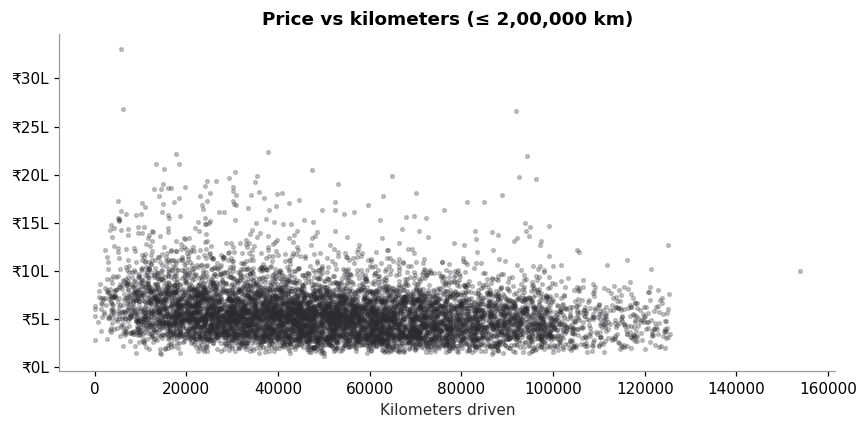

In [6]:
d = df[df["Distance"] <= 200_000]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(d["Distance"], d["Price"], s=6, alpha=.25, color=DARK)
ax.yaxis.set_major_formatter(lakh); ax.set_xlabel("Kilometers driven"); ax.set_title("Price vs kilometers (≤ 2,00,000 km)")
plt.tight_layout()
print("Listings above 2,00,000 km:", (df.Distance > 200_000).sum(), "| max km:", f"{df.Distance.max():,}")

Price tends to fall as mileage rises, but the linear relationship is weak (correlation ≈ −0.20, see section 7). Only 2 listings exceed 2,00,000 km, the largest being 9,71,212 km, so the data is very thin there; the app warns above 2,00,000 km for that reason.

## 5. Fuel, transmission, body type and ownership

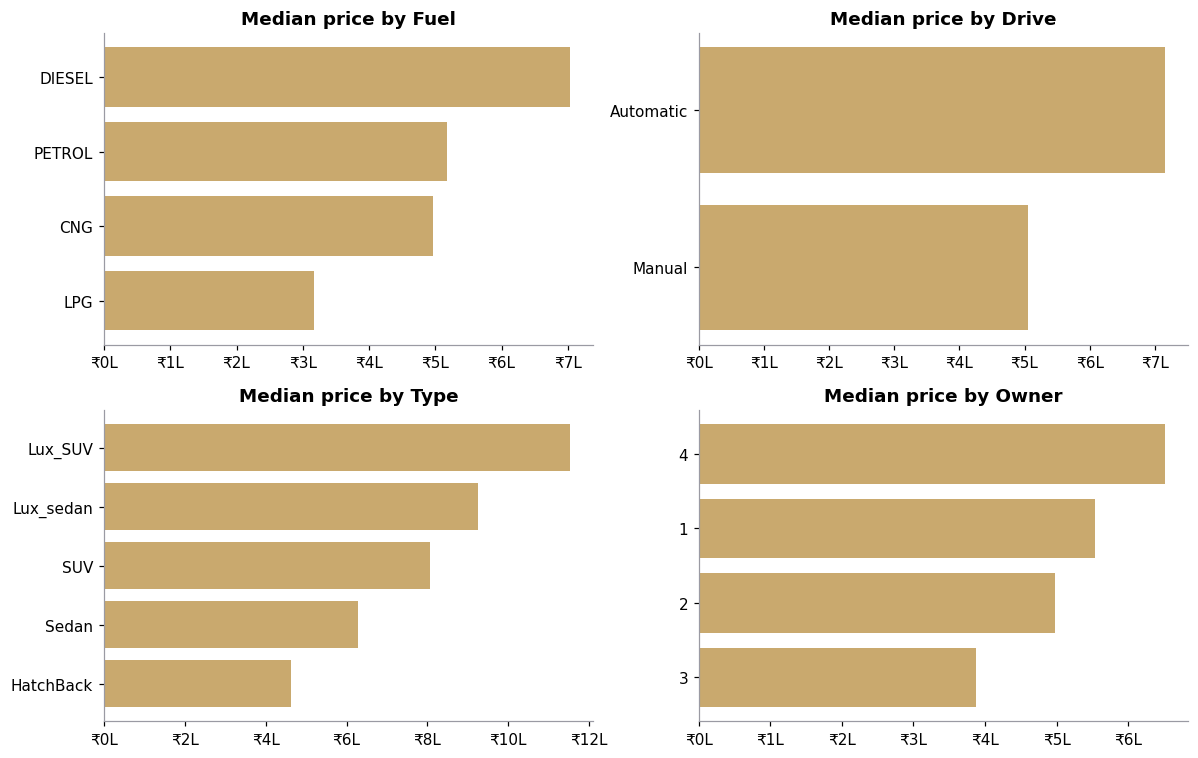

,size,median
Fuel,,
CNG,535,496000
DIESEL,1066,703000
LPG,1,317000
PETROL,6412,517000


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Fuel", "Drive", "Type", "Owner"]):
    s = df.groupby(col)["Price"].median().sort_values()
    ax.barh(s.index.astype(str), s.values, color=ACCENT)
    ax.xaxis.set_major_formatter(lakh); ax.set_title(f"Median price by {col}")
plt.tight_layout()
df.groupby("Fuel")["Price"].agg(["size", "median"]).astype(int)

Note that `LPG` has a single listing, so it cannot be estimated reliably, and `Owner = 4` also has just one row.

In [8]:
for c in ["Drive", "Type", "Owner"]:
    print(df[c].value_counts().to_string(), "\n")

Drive
Manual       6455
Automatic    1559 

Type
HatchBack    5080
Sedan        1621
SUV          1171
Lux_SUV        80
Lux_sedan      62 

Owner
1    5811
2    2001
3     201
4       1 



## 6. Brands

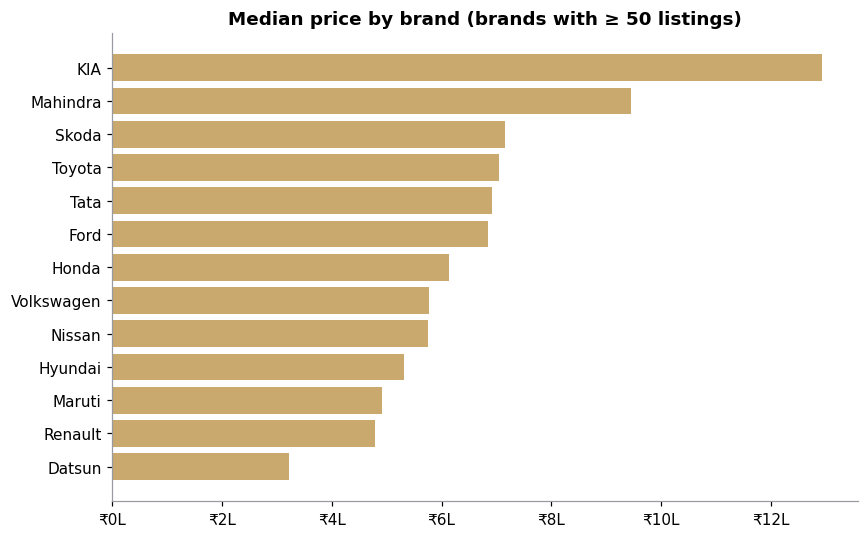

,median,size
Brand,,
KIA,1294000,65
Mahindra,945000,153
Skoda,715000,74
Toyota,704000,173
Tata,692000,350
Ford,684000,175
Honda,614000,829
Volkswagen,577000,182
Nissan,576000,64


In [9]:
b = df.groupby("Brand")["Price"].agg(["median", "size"]).query("size >= 50").sort_values("median")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(b.index, b["median"], color=ACCENT)
ax.xaxis.set_major_formatter(lakh); ax.set_title("Median price by brand (brands with ≥ 50 listings)")
plt.tight_layout()
b.astype(int).sort_values("median", ascending=False)

## 7. Numeric correlations with price

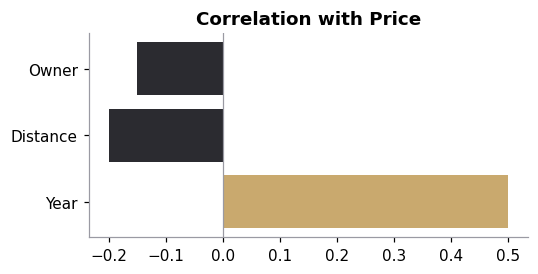

Year        0.50
Distance   -0.20
Owner      -0.15
Name: Price, dtype: float64

In [10]:
corr = df[["Price", "Year", "Distance", "Owner"]].corr()["Price"].drop("Price").round(2)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.barh(corr.index, corr.values, color=[ACCENT if v > 0 else DARK for v in corr.values])
ax.axvline(0, color=MUTED, lw=.8); ax.set_title("Correlation with Price")
plt.tight_layout()
corr

## 8. Takeaways
- **Price is right-skewed** (median ₹5.35 lakh, skew 1.75), so a log-price target is worth testing.
- **Year is the strongest numeric signal** (correlation ≈ 0.50): median price rises from about ₹2.2 lakh for 2010 cars to ₹7.4 lakh for 2022 cars.
- **Mileage and ownership matter less** on their own (correlations ≈ −0.20 and −0.15).
- **Diesel listings are priced higher** (median ₹7.03 lakh vs ₹5.17 lakh for petrol and ₹4.96 lakh for CNG), though this is entangled with which car models and body types run on diesel.
- **Brand and model matter:** KIA and Mahindra have the highest median prices among brands with 50+ listings, and Maruti and Hyundai make up about 68% of all listings.
- **Thin data in places:** `LPG`, `Owner = 4` and `Year = 2023` each have a single row, and only 2 cars exceed 2,00,000 km. Predictions in those corners are unreliable.
- **No trim/variant, location or condition columns** — a likely reason several different models plateau at similar accuracy (see `train.py`).